# 04 — Part E base model training


## 1. Fix the validation design

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if not (project_root / 'data' / 'processed' / 'loan_default_cleaned.csv').is_file():
    raise FileNotFoundError('Open this notebook from the project root or its notebooks folder.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_preparation import BASELINE_EXCLUSIONS, TrainingFoldPreprocessor, split_loan_data

df = pd.read_csv(project_root / 'data' / 'processed' / 'loan_default_cleaned.csv')

tables = project_root / 'outputs' / 'tables' / 'part_e'
figures = project_root / 'outputs' / 'figures' / 'part_e'
tables.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

import platform
import sklearn
import xgboost
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier
from src.model_validation import evaluate_models

SEED = 42
WORKERS = 4
X_dev, X_holdout, y_dev, _ = split_loan_data(df)
assert X_dev.index.intersection(X_holdout.index).empty
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_dev, y_dev))
print(f'{len(X_dev):,} development rows ({y_dev.mean():.2%} defaults) | {len(X_holdout):,} reserved rows')
print(f'{platform.machine()} / {platform.system()} | sklearn {sklearn.__version__} | XGBoost {xgboost.__version__}')

118,936 development rows (24.64% defaults) | 29,734 reserved rows
arm64 / Darwin | sklearn 1.9.0 | XGBoost 3.4.1


## 2. Logistic Regression, Random Forest, XGBoost Training


In [2]:
models = {
    'Logistic Regression': LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=10,
        random_state=SEED, n_jobs=WORKERS,
    ),
    'XGBoost': XGBClassifier(
        objective='binary:logistic', eval_metric='logloss', tree_method='hist',
        n_estimators=120, max_depth=4, learning_rate=0.1,
        random_state=SEED, n_jobs=WORKERS,
    ),
}
reference = DummyClassifier(strategy='most_frequent')
for name, estimator in models.items():
    print(f'{name}: {estimator}')

Logistic Regression: LogisticRegression(max_iter=1000)
Random Forest: RandomForestClassifier(max_depth=12, min_samples_leaf=10, n_jobs=4,
                       random_state=42)
XGBoost: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=120, n_jobs=4,
              num_parallel_tree=None, ...)


## 4. Train on shared folds


In [3]:
scores, oof, coefficients, importance, screens = evaluate_models(X_dev, y_dev, folds, models, reference, SEED)
assert len(scores) == 33
assert (scores[['tn', 'fp', 'fn', 'tp']].sum(axis=1) > 0).all()
assert (scores['top10_tp'] <= scores['top10_flagged']).all()
scores.to_csv(tables / 'fold_metrics.csv', index=False)
oof.to_csv(tables / 'oof_probabilities.csv', float_format='%.10g')
screens.to_csv(tables / 'fold_proxy_screen.csv', index=False)
display(screens.query('flagged')[['fold', 'feature', 'group', 'support', 'default_rate']])

Completed fold 1


Completed fold 2


Completed fold 3


,fold,feature,group,support,default_rate
34,1,credit_type,EQUI,8091,1.000000
45,1,age,<missing>,107,1.000000
48,1,submission_of_application,<missing>,107,1.000000
88,2,credit_type,EQUI,8111,0.999877
98,2,age,<missing>,91,1.000000
101,2,submission_of_application,<missing>,91,1.000000
140,3,credit_type,EQUI,8114,0.999877
151,3,age,<missing>,114,1.000000
154,3,submission_of_application,<missing>,114,1.000000


## 6. Compare models and preparation variants



,ap_mean,ap_std,pooled_oof_ap,roc_auc_mean,accuracy_mean,precision_mean,recall_mean,f1_mean,top10_precision,top10_recall,fp,fn
model,,,,,,,,,,,,
XGBoost,0.5749,0.0053,0.5748,0.7484,0.7964,0.7729,0.2459,0.3731,0.7100,0.2881,2117,22103
Random Forest,0.5565,0.0073,0.5562,0.7381,0.7910,0.8203,0.1947,0.3147,0.6881,0.2792,1251,23603
Logistic Regression,0.4731,0.0056,0.4728,0.6984,0.7740,0.6654,0.1667,0.2666,0.5889,0.2390,2458,24424
Majority reference,0.2464,0.0000,0.2464,0.5000,0.7536,0.0000,0.0000,0.0000,0.2424,0.0984,0,29311


ap_mean  ap_std  ap_delta_pp  roc_auc_mean  \
model               variant                                                
Logistic Regression Raw        0.4731  0.0056       0.0000        0.6984   
                    Log        0.5193  0.0064       4.6197        0.7156   
                    Weighted   0.4675  0.0054      -0.5519        0.6973   
                    PCA 95%    0.4191  0.0045      -5.3920        0.6729   
Random Forest       Raw        0.5565  0.0073       0.0000        0.7381   
                    Log        0.5569  0.0069       0.0402        0.7384   
                    Weighted   0.5522  0.0066      -0.4226        0.7403   
XGBoost             Raw        0.5749  0.0053       0.0000        0.7484   
                    Log        0.5749  0.0053       0.0000        0.7484   
                    Weighted   0.5742  0.0054      -0.0664        0.7496   

                              recall_mean  recall_delta_pp  precision_mean  \
model               variant                                                  
Logistic Regression Raw            0.1667           0.0000          0.6654   
                    Log            0.2106           4.3840          0.7112   
                    Weighted       0.5928          42.6052          0.3840   
                    PCA 95%        0.0979          -6.8848          0.6163   
Random Forest       Raw            0.1947           0.0000          0.8203   
                    Log            0.1970           0.2252          0.8129   
                    Weighted       0.6123          41.7591          0.4347   
XGBoost             Raw            0.2459           0.0000          0.7729   
                    Log            0.2459           0.0000          0.7729   
                    Weighted       0.6057          35.9763          0.4486   

                              precision_delta_pp  f1_mean  \
model               variant                                 
Logistic Regression Raw                   0.0000   0.2666   
                    Log                   4.5800   0.3249   
                    Weighted            -28.1418   0.4661   
                    PCA 95%              -4.9156   0.1689   
Random Forest       Raw                   0.0000   0.3147   
                    Log                  -0.7437   0.3171   
                    Weighted            -38.5657   0.5084   
XGBoost             Raw                   0.0000   0.3731   
                    Log                   0.0000   0.3731   
                    Weighted            -32.4354   0.5154   

                              encoded_features_mean  model_features_mean  \
model               variant                                                
Logistic Regression Raw                        47.0                 47.0   
                    Log                        47.0                 47.0   
                    Weighted                   47.0                 47.0   
                    PCA 95%                    47.0                 14.0   
Random Forest       Raw                        47.0                 47.0   
                    Log                        47.0                 47.0   
                    Weighted                   47.0                 47.0   
XGBoost             Raw                        47.0                 47.0   
                    Log                        47.0                 47.0   
                    Weighted                   47.0                 47.0   

                                 fp     fn  
model               variant                 
Logistic Regression Raw        2458  24424  
                    Log        2506  23139  
                    Weighted  27871  11936  
                    PCA 95%    1786  26442  
Random Forest       Raw        1251  23603  
                    Log        1330  23537  
                    Weighted  23341  11363  
XGBoost             Raw        2117  22103  
                    Log        2117  22103  
                    Weighted  21823  11

variant                     Log  PCA 95%  Weighted
model               fold                          
Logistic Regression 1     4.501   -5.122    -0.529
                    2     4.628   -5.354    -0.542
                    3     4.730   -5.700    -0.584
Random Forest       1     0.041      NaN    -0.322
                    2    -0.092      NaN    -0.433
                    3     0.172      NaN    -0.513
XGBoost             1     0.000      NaN    -0.082
                    2     0.000      NaN    -0.046
                    3     0.000      NaN    -0.072

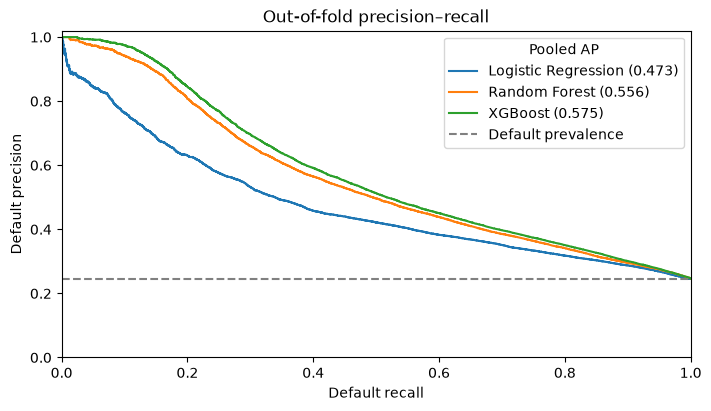

In [4]:
metrics = ['ap', 'roc_auc', 'accuracy', 'precision', 'recall', 'f1', 'train_ap',
           'fit_seconds', 'prediction_ms_per_1000']
scores['ap_gap'] = scores['train_ap'] - scores['ap']
grouped = scores.groupby(['model', 'variant'], sort=False)
summary = grouped[metrics + ['ap_gap', 'encoded_features', 'model_features']].agg(['mean', 'std'])
summary.columns = ['_'.join(c) for c in summary.columns]
counts = grouped[['fp', 'fn', 'top10_flagged', 'top10_tp', 'validation_defaults']].sum()
summary = summary.join(counts)
summary['top10_precision'] = summary['top10_tp'] / summary['top10_flagged']
summary['top10_recall'] = summary['top10_tp'] / summary['validation_defaults']
summary.to_csv(tables / 'cv_summary.csv')

baseline = summary.xs('Raw', level='variant').copy()
baseline['pooled_oof_ap'] = [average_precision_score(oof['status'], oof[name]) for name in baseline.index]
baseline = baseline.sort_values('ap_mean', ascending=False)
baseline.to_csv(tables / 'baseline_comparison.csv')
display(baseline[['ap_mean', 'ap_std', 'pooled_oof_ap', 'roc_auc_mean', 'accuracy_mean',
                  'precision_mean', 'recall_mean', 'f1_mean', 'top10_precision',
                  'top10_recall', 'fp', 'fn']].round(4))

comparison = summary.loc[list(models)].join(
    baseline[['ap_mean', 'recall_mean', 'precision_mean']].add_suffix('_raw'), on='model')
for metric in ['ap', 'recall', 'precision']:
    comparison[f'{metric}_delta_pp'] = 100 * (comparison[f'{metric}_mean'] - comparison[f'{metric}_mean_raw'])
fields = ['ap_mean', 'ap_std', 'ap_delta_pp', 'roc_auc_mean', 'recall_mean', 'recall_delta_pp',
          'precision_mean', 'precision_delta_pp', 'f1_mean', 'encoded_features_mean', 'model_features_mean', 'fp', 'fn']
part_d_tables = tables.parent / 'part_d'
part_d_tables.mkdir(exist_ok=True)
comparison[fields].to_csv(part_d_tables / 'preprocessing_comparison.csv')
display(comparison[fields].round(4))
paired_ap = scores[scores['model'].isin(models)].pivot(index=['model', 'fold'], columns='variant', values='ap')
paired_ap = 100 * paired_ap.drop(columns='Raw').subtract(paired_ap['Raw'], axis=0)
paired_ap.to_csv(part_d_tables / 'paired_ap_differences.csv')
display(paired_ap.round(3))

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
for name in models:
    precision, recall, _ = precision_recall_curve(oof['status'], oof[name])
    ax.plot(recall, precision, label=f'{name} ({baseline.loc[name, "pooled_oof_ap"]:.3f})')
ax.axhline(y_dev.mean(), linestyle='--', color='grey', label='Default prevalence')
ax.set(title='Out-of-fold precision–recall', xlabel='Default recall', ylabel='Default precision',
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(title='Pooled AP')
fig.savefig(figures / 'precision_recall_oof.png', dpi=160)
plt.show()

## 7. Interpret the fitted models

,mean,std,count
feature,,,
lump_sum_payment_not_lpsm,-1.0753,0.0253,3
income,-0.4080,0.0187,3
construction_type_sb,-0.3931,0.0744,3
secured_by_home,-0.3931,0.0744,3
security_type_direct,-0.3931,0.0744,3
lump_sum_payment_lpsm,1.4932,0.0447,3
neg_amortization_neg_amm,0.8141,0.0268,3
construction_type_mh,0.8110,0.1236,3
secured_by_land,0.8110,0.1236,3


,mean,std,count
feature,,,
income,0.0868,0.0334,3
neg_amortization,0.0852,0.0120,3
lump_sum_payment,0.0814,0.0196,3
co_applicant_credit_type,0.0677,0.0124,3
loan_limit,0.0220,0.0045,3
credit_worthiness,0.0199,0.0111,3
loan_purpose,0.0115,0.0039,3
loan_amount,0.0105,0.0037,3


,mean,std,count
feature,,,
income,0.2004,0.0472,3
loan_amount,0.0789,0.0053,3
co_applicant_credit_type,0.0766,0.0118,3
neg_amortization,0.0706,0.0083,3
lump_sum_payment,0.0683,0.0151,3
loan_limit,0.0236,0.0066,3
credit_worthiness,0.0199,0.0061,3
loan_purpose,0.0198,0.0017,3


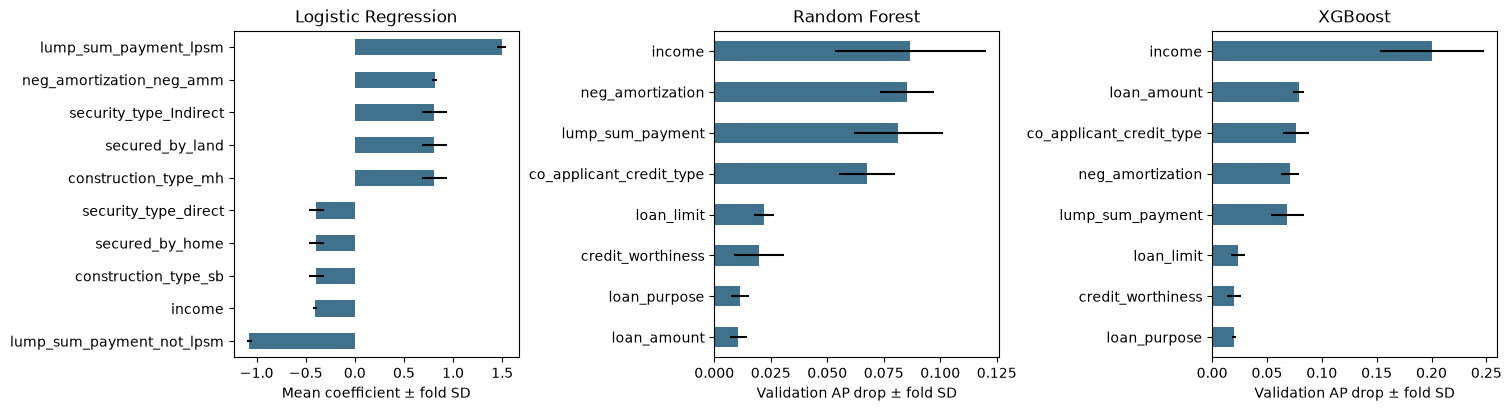

In [5]:
coefficients.to_csv(tables / 'logistic_fold_coefficients.csv', index=False)
importance.to_csv(tables / 'tree_fold_permutation_importance.csv', index=False)
coefficient_summary = coefficients.groupby('feature')['coefficient'].agg(['mean', 'std', 'count'])
importance_summary = importance.groupby(['model', 'feature'])['mean_ap_drop'].agg(['mean', 'std', 'count'])
coefficient_summary.to_csv(tables / 'logistic_coefficients.csv')
importance_summary.to_csv(tables / 'tree_permutation_importance.csv')
stable_coefficients = coefficient_summary.query('count == 3')
tails = pd.concat([stable_coefficients.nsmallest(5, 'mean'), stable_coefficients.nlargest(5, 'mean')])
display(tails.round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
tails.sort_values('mean').plot.barh(y='mean', xerr='std', legend=False, ax=axes[0], color='#40728E')
axes[0].set(title='Logistic Regression', xlabel='Mean coefficient ± fold SD', ylabel='')
for ax, name in zip(axes[1:], ['Random Forest', 'XGBoost']):
    top = importance_summary.loc[name].nlargest(8, 'mean').sort_values('mean')
    display(top.sort_values('mean', ascending=False).round(4))
    top.plot.barh(y='mean', xerr='std', legend=False, ax=ax, color='#40728E')
    ax.set(title=name, xlabel='Validation AP drop ± fold SD', ylabel='')
fig.savefig(figures / 'model_interpretability.png', dpi=160)
plt.show()

## 8. Compare cost and overfitting

In [6]:
cost_fields = ['fit_seconds_mean', 'fit_seconds_std', 'prediction_ms_per_1000_mean',
               'prediction_ms_per_1000_std', 'model_features_mean',
               'train_ap_mean', 'ap_mean', 'ap_gap_mean', 'ap_gap_std']
cost = baseline.loc[list(models), cost_fields]
cost.to_csv(tables / 'computational_comparison.csv')
display(cost.round(4))

,fit_seconds_mean,fit_seconds_std,prediction_ms_per_1000_mean,prediction_ms_per_1000_std,model_features_mean,train_ap_mean,ap_mean,ap_gap_mean,ap_gap_std
model,,,,,,,,,
Logistic Regression,0.9834,0.0564,1.5451,0.0077,47.0,0.4738,0.4731,0.0008,0.0090
Random Forest,1.4607,0.0133,3.0997,0.0839,47.0,0.5812,0.5565,0.0247,0.0085
XGBoost,0.8057,0.0062,1.7292,0.0231,47.0,0.5899,0.5749,0.0150,0.0084


## 9. Summarise the evidence and limits

In [7]:
for name in baseline.index.intersection(models):
    raw = baseline.loc[name]
    weighted = comparison.loc[(name, 'Weighted')]
    log_variant = comparison.loc[(name, 'Log')]
    print(f'{name}: mean AP {raw.ap_mean:.3f}, top-10% recall {raw.top10_recall:.1%}, '
          f'train–validation AP gap {raw.ap_gap_mean:.3f}. '
          f'Log AP change {log_variant.ap_delta_pp:+.2f} pp. '
          f'Weighted recall {raw.recall_mean:.1%} → {weighted.recall_mean:.1%}; '
          f'precision {raw.precision_mean:.1%} → {weighted.precision_mean:.1%}.')
pca = comparison.loc[('Logistic Regression', 'PCA 95%')]
print(f'PCA retained {pca.model_features_mean:.1f} of {pca.encoded_features_mean:.1f} features on average; '
      f'AP changed by {pca.ap_delta_pp:+.2f} pp versus raw Logistic Regression.')

XGBoost: mean AP 0.575, top-10% recall 28.8%, train–validation AP gap 0.015. Log AP change +0.00 pp. Weighted recall 24.6% → 60.6%; precision 77.3% → 44.9%.
Random Forest: mean AP 0.556, top-10% recall 27.9%, train–validation AP gap 0.025. Log AP change +0.04 pp. Weighted recall 19.5% → 61.2%; precision 82.0% → 43.5%.
Logistic Regression: mean AP 0.473, top-10% recall 23.9%, train–validation AP gap 0.001. Log AP change +4.62 pp. Weighted recall 16.7% → 59.3%; precision 66.5% → 38.4%.
PCA retained 14.0 of 47.0 features on average; AP changed by -5.39 pp versus raw Logistic Regression.
